# The Quant Pipeline: From Fundamental Data to a Machine Learning-Based Long/Short Portfolio

## Part 1: Data Engineering and Preparation

### Research question

Can a machine learning model trained on company fundamentals identify stocks that outperform the S&P 500, and can those predictions later be translated into a long/short portfolio with meaningful risk-adjusted performance?

This first section prepares the raw `keystats.csv` data for exploratory analysis and later modeling. The main goals are to understand the structure of the data, handle observations that cannot be labeled, create the binary outperformance target, organize observations by calendar quarter, and inspect the predictor variables before the chronological train/test split.


### 1. Import libraries and load the dataset

The project uses Pandas and NumPy for data preparation and Matplotlib for visualizations. The column names are standardized to the format already used throughout this notebook.


In [1]:
# reading the file
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("keystats.csv")
df.columns = df.columns.str.capitalize()

df


/Users/souravchakraborty/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/souravchakraborty/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


,Date,Unix,Ticker,Price,Stock_p_change,Sp500,Sp500_p_change,Market cap,Enterprise value,Trailing p/e,...,200-day moving average,Avg vol (3 month),Shares outstanding,Float,% held by insiders,% held by institutions,Shares short (as of,Short ratio,Short % of float,Shares short (prior month)
0,2007-07-11,1184104768,ctas,33.538876,-33.02,122.084023,-15.90,6.350000e+09,7.080000e+09,19.13,...,39.30,1064470.0,158650000.0,135580000.0,17.81,64.70,4970000.0,4.200,3.70,4490000.0
1,2006-02-28,1141130339,ctas,34.026257,-0.79,100.297188,11.94,6.910000e+09,7.160000e+09,22.55,...,41.44,940276.0,168020000.0,140190000.0,16.59,66.20,3460000.0,3.400,2.50,4600000.0
2,2005-04-20,1113982724,ctas,31.885536,9.65,87.811470,17.27,6.750000e+09,7.020000e+09,23.35,...,43.13,1027318.0,172090000.0,122500000.0,28.82,65.87,6170000.0,6.479,5.04,6360000.0
3,2005-02-22,1109048563,ctas,35.317966,-4.10,91.157219,10.92,7.550000e+09,7.670000e+09,26.61,...,43.75,994136.0,171720000.0,122200000.0,28.84,63.20,5420000.0,4.740,4.44,4640000.0
4,2013-04-26,1366969360,ctas,41.474506,30.78,143.779022,20.10,5.480000e+09,6.550000e+09,18.46,...,42.70,580981.0,122520000.0,102370000.0,16.36,74.60,5060000.0,8.000,5.60,5860000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8677,2009-01-12,1231774186,vno,27.035572,41.34,72.243233,33.74,8.020000e+09,1.999000e+10,12.77,...,78.02,4530000.0,154350000.0,135220000.0,10.69,90.50,11070000.0,2.000,7.70,21800.0
8678,2009-09-18,1253239115,vno,37.499359,31.57,90.236214,7.49,1.214000e+10,2.328000e+10,NaN,...,46.64,3252510.0,178560000.0,163040000.0,9.83,93.70,13540000.0,4.900,8.10,14740000.0
8679,2012-11-05,1352070839,vno,48.554001,18.85,127.412491,26.98,1.504000e+10,5.550000e+09,26.99,...,82.61,988767.0,185810000.0,168560000.0,19.87,81.30,3010000.0,2.900,1.80,3150000.0
8680,2013-04-29,1367217482,vno,54.483345,21.23,144.742172,20.24,1.613000e+10,1.631000e+10,29.35,...,81.58,1027800.0,186730000.0,162270000.0,9.74,92.20,3280000.0,3.300,2.20,3460000.0


### 2. Initial structure of the dataset

The following cells inspect the number of observations and variables, the column names, data types, missing values, and descriptive statistics. This establishes what is available before any cleaning decisions are made.


In [2]:
print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Number of rows and columns: (8682, 48)

Column names:
['Date', 'Unix', 'Ticker', 'Price', 'Stock_p_change', 'Sp500', 'Sp500_p_change', 'Market cap', 'Enterprise value', 'Trailing p/e', 'Forward p/e', 'Peg ratio', 'Price/sales', 'Price/book', 'Enterprise value/revenue', 'Enterprise value/ebitda', 'Profit margin', 'Operating margin', 'Return on assets', 'Return on equity', 'Revenue', 'Revenue per share', 'Qtrly revenue growth', 'Gross profit', 'Ebitda', 'Net income avl to common', 'Diluted eps', 'Qtrly earnings growth', 'Total cash', 'Total cash per share', 'Total debt', 'Total debt/equity', 'Current ratio', 'Book value per share', 'Operating cash flow', 'Levered free cash flow', 'Beta', '50-day moving average', '200-day moving average', 'Avg vol (3 month)', 'Shares outstanding', 'Float', '% held by insiders', '% held by institutions', 'Shares short (as of', 'Short ratio', 'Short % of float', 'Shares short (prior month)']


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8682 entries, 0 to 8681
Data columns (total 48 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        8682 non-null   object 
 1   Unix                        8682 non-null   int64  
 2   Ticker                      8682 non-null   object 
 3   Price                       8578 non-null   float64
 4   Stock_p_change              8578 non-null   float64
 5   Sp500                       8682 non-null   float64
 6   Sp500_p_change              8682 non-null   float64
 7   Market cap                  8593 non-null   float64
 8   Enterprise value            8548 non-null   float64
 9   Trailing p/e                7887 non-null   float64
 10  Forward p/e                 8350 non-null   float64
 11  Peg ratio                   8215 non-null   float64
 12  Price/sales                 8565 non-null   float64
 13  Price/book                  8441 

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Unix,8682.0,1.219222e+09,9.739501e+07,1.065084e+09,1.138921e+09,1.197831e+09,1.321592e+09,1.378419e+09
Price,8578.0,3.876936e+01,5.890436e+01,3.500000e-02,1.710935e+01,2.776132e+01,4.325834e+01,1.152803e+03
Stock_p_change,8578.0,1.765658e+01,4.559408e+01,-9.761000e+01,-4.427500e+00,1.323000e+01,3.299750e+01,6.483900e+02
Sp500,8682.0,1.067463e+02,1.996734e+01,5.658983e+01,9.105231e+01,1.086048e+02,1.196386e+02,1.546514e+02
Sp500_p_change,8682.0,9.832906e+00,1.613163e+01,-4.615000e+01,6.052500e+00,1.310000e+01,1.939750e+01,7.194000e+01
Market cap,8593.0,3.989195e+10,6.591613e+10,7.840000e+06,6.320000e+09,1.424000e+10,3.953000e+10,6.560000e+11
Enterprise value,8548.0,4.661039e+10,9.277280e+10,-5.130000e+11,7.250000e+09,1.636500e+10,4.727000e+10,8.990000e+11
Trailing p/e,7887.0,3.971043e+01,3.665257e+02,0.000000e+00,1.301500e+01,1.805000e+01,2.522500e+01,1.279500e+04
Forward p/e,8350.0,1.730121e+01,2.894064e+01,0.000000e+00,1.102250e+01,1.420000e+01,1.796750e+01,1.792000e+03
Peg ratio,8215.0,1.738963e+00,1.113180e+01,-3.425000e+02,1.010000e+00,1.350000e+00,1.830000e+00,6.850000e+02


In [5]:
# missing values in the raw dataset
print(df.isnull().sum().sort_values())


Date                             0
Unix                             0
Ticker                           0
Sp500                            0
Sp500_p_change                   0
Book value per share            66
Avg vol (3 month)               71
Net income avl to common        73
Revenue                         80
Shares outstanding              89
Market cap                      89
Shares short (as of             90
Shares short (prior month)      93
Short ratio                     94
Revenue per share               96
Diluted eps                    103
Price                          104
Stock_p_change                 104
50-day moving average          108
200-day moving average         115
Price/sales                    117
Total cash per share           125
Total debt                     126
Profit margin                  133
Enterprise value               134
Total cash                     136
Enterprise value/revenue       156
Operating margin               196
% held by institutio

The dataset contains stock identifiers, dates, market information, forward stock and S&P 500 percentage changes, and a broad set of company fundamentals. Several features contain missing values, with the largest gaps concentrated in quarterly growth and cash-flow variables. The forward stock return is also missing for a small number of observations, which must be handled before the target can be created.


### 3. Check duplicate records and repeated ticker-date combinations

A complete duplicate would indicate that the same row appears more than once. A repeated ticker-date combination is different: the same stock may appear more than once on the same date while some fundamental values differ. These records are inspected rather than automatically deleted.


In [6]:
print("Number of completely duplicated rows:", df.duplicated().sum())

duplicate_ticker_dates = df.duplicated(subset=["Ticker", "Date"], keep=False)
print("Number of rows involved in repeated ticker-date combinations:", duplicate_ticker_dates.sum())

df.loc[duplicate_ticker_dates, :].sort_values(["Ticker", "Date"]).head(20)


Number of completely duplicated rows: 0
Number of rows involved in repeated ticker-date combinations: 148


,Date,Unix,Ticker,Price,Stock_p_change,Sp500,Sp500_p_change,Market cap,Enterprise value,Trailing p/e,...,200-day moving average,Avg vol (3 month),Shares outstanding,Float,% held by insiders,% held by institutions,Shares short (as of,Short ratio,Short % of float,Shares short (prior month)
168,2011-09-24,1316794537,aapl,39.099064,78.50,99.845856,31.23,3.750000e+11,3.440000e+11,15.99,...,355.85,20920500.0,9.270900e+08,9.210500e+08,0.65,70.8,15160000.0,0.6,NaN,12540000.0
193,2011-09-24,1316814215,aapl,39.099064,78.50,99.845856,31.23,3.750000e+11,3.460000e+11,15.99,...,356.19,20884500.0,9.270900e+08,9.210500e+08,0.65,70.8,15160000.0,0.6,NaN,12540000.0
3823,2006-08-22,1156200245,acn,22.094664,45.07,102.631844,14.77,1.649000e+10,1.355000e+10,20.22,...,29.41,2239080.0,5.770600e+08,5.474000e+08,3.18,47.4,3080000.0,1.2,0.5,2730000.0
3832,2006-08-22,1156179041,acn,22.094664,45.07,102.631844,14.77,1.649000e+10,1.386000e+10,20.22,...,29.41,2239080.0,5.770600e+08,5.474000e+08,3.18,47.4,3080000.0,1.2,0.5,2730000.0
4783,2006-04-13,1144917267,amd,31.799999,-57.33,101.072968,14.99,1.570000e+10,1.661000e+10,82.63,...,31.27,17705600.0,4.808900e+08,3.675900e+08,0.12,78.9,17840000.0,1.1,3.7,17250000.0
4792,2006-04-13,1144867937,amd,31.799999,-57.33,101.072968,14.99,1.703000e+10,1.620000e+10,89.67,...,31.27,17705600.0,4.808900e+08,3.675900e+08,0.12,78.9,17840000.0,1.1,3.7,17250000.0
64,2006-04-12,1144788074,amzn,36.130001,16.99,101.206490,14.32,1.503000e+10,1.478000e+10,42.78,...,42.60,6453840.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0
107,2006-04-12,1144830231,amzn,36.130001,16.99,101.206490,14.32,1.514000e+10,1.478000e+10,43.08,...,42.60,6453840.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0
62,2006-04-27,1146070354,amzn,35.740002,75.15,102.894806,16.23,1.492000e+10,1.444000e+10,42.46,...,42.00,6385290.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0
104,2006-04-27,1146153315,amzn,35.740002,75.15,102.894806,16.23,1.490000e+10,1.444000e+10,42.40,...,42.00,6385290.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0


The dataset does not contain completely duplicated rows, but some ticker-date combinations appear more than once. Because the repeated rows can contain slightly different fundamental values, they are retained at this stage instead of being treated as exact duplicates.


### 4. Convert dates, sort chronologically, and standardize tickers

Financial observations are time ordered, so the date column is converted to a proper datetime type and the data are sorted from earliest to latest. Ticker symbols are stripped of extra spaces and converted to uppercase so that formatting differences do not create artificial duplicates.


In [7]:
# Convert Date from text to a datetime variable
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Missing or invalid dates:", df["Date"].isna().sum())

# Standardize tickers and sort the dataset chronologically
df["Ticker"] = df["Ticker"].str.strip().str.upper()
df = df.sort_values(by=["Date", "Ticker"]).reset_index(drop=True)

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())
print("Number of unique stocks:", df["Ticker"].nunique())

df.head(20)


Missing or invalid dates: 0
Earliest date: 2003-10-02 00:00:00
Latest date: 2013-09-06 00:00:00
Number of unique stocks: 471


,Date,Unix,Ticker,Price,Stock_p_change,Sp500,Sp500_p_change,Market cap,Enterprise value,Trailing p/e,...,200-day moving average,Avg vol (3 month),Shares outstanding,Float,% held by insiders,% held by institutions,Shares short (as of,Short ratio,Short % of float,Shares short (prior month)
0,2003-10-02,1065085404,AMD,11.690000,14.88,76.901154,12.72,4.060000e+09,4.800000e+09,NaN,...,7.42,10463909.0,3.469600e+08,3.366000e+08,2.99,59.10,39840000.0,2.684,11.84,38840000.0
1,2003-10-02,1065083875,AMGN,57.050285,-12.68,76.901154,12.72,8.504000e+10,8.365000e+10,NaN,...,60.80,7888909.0,1.290000e+09,1.170000e+09,9.71,71.46,28000000.0,3.881,2.40,28230000.0
2,2003-10-02,1065087022,CVS,13.475180,35.60,76.901154,12.72,1.265000e+10,1.340000e+10,17.18,...,26.84,1932545.0,3.947100e+08,3.913000e+08,0.86,86.90,5140000.0,2.685,1.31,6230000.0
3,2003-10-02,1065087714,DIS,16.915346,11.27,76.901154,12.72,4.260000e+10,5.512000e+10,40.84,...,18.89,8466181.0,2.040000e+09,2.010000e+09,1.46,65.35,47860000.0,5.478,2.38,54720000.0
4,2003-10-02,1065088426,EBAY,11.595118,67.77,76.901154,12.72,3.511000e+10,3.341000e+10,112.78,...,46.39,12037181.0,6.420800e+08,4.946000e+08,22.97,64.41,34720000.0,2.904,7.02,36400000.0
5,2003-10-02,1065084099,MSFT,18.900982,-0.03,76.901154,12.72,3.060000e+11,2.590000e+11,31.00,...,25.87,54106318.0,1.082000e+10,9.200000e+09,14.97,53.12,123630000.0,2.234,1.34,108430000.0
6,2003-10-02,1065093642,NKE,3.410104,40.13,76.901154,12.72,1.639000e+10,1.629000e+10,21.04,...,51.38,1293818.0,2.637300e+08,1.311000e+08,50.29,55.17,7560000.0,7.787,5.77,6840000.0
7,2003-10-02,1065094861,NSC,13.572272,63.12,76.901154,12.72,7.360000e+09,1.478000e+10,15.43,...,19.64,1443818.0,3.902100e+08,3.369000e+08,13.66,68.26,2840000.0,1.861,0.84,3260000.0
8,2003-10-03,1065170920,ADSK,9.035097,175.89,77.606743,11.70,2.060000e+09,1.680000e+09,45.68,...,15.66,1072500.0,1.116000e+08,1.063000e+08,4.75,91.78,2220000.0,1.680,2.09,2220000.0
9,2003-10-03,1065173027,AES,6.781198,27.83,77.606743,11.70,4.930000e+09,2.367000e+10,NaN,...,5.43,2342272.0,6.197300e+08,5.352000e+08,13.64,69.94,8570000.0,4.499,1.60,9610000.0


The data cover approximately ten years and include hundreds of unique stocks. Sorting by date is important because the later modeling stage must train on earlier information and evaluate performance on later information.


### 5. Remove observations without a usable target

The project defines outperformance by comparing each stock's forward percentage change with the corresponding S&P 500 forward percentage change. If `Stock_p_change` is missing, the true target cannot be determined. Imputing a forward return would create an invented label, so these rows are removed rather than filled with a mean or median.


In [8]:
print("Missing target values before removal:")
print(df[["Stock_p_change", "Sp500_p_change"]].isnull().sum())

Original_df = df.copy()  # backup copy before dropping unusable target rows

df = df.dropna(subset=["Stock_p_change"]).reset_index(drop=True)

print("\nMissing target values after removal:")
print(df[["Stock_p_change", "Sp500_p_change"]].isnull().sum())

print("\nRows removed:", len(Original_df) - len(df))
print("Rows remaining:", len(df))


Missing target values before removal:
Stock_p_change    104
Sp500_p_change      0
dtype: int64

Missing target values after removal:
Stock_p_change    0
Sp500_p_change    0
dtype: int64

Rows removed: 104
Rows remaining: 8578


Only a small portion of the observations is lost. Removing these rows is preferable to assigning artificial future returns because the Random Forest must be trained on valid labels.


### 6. Construct the binary outperformance target

The target variable is defined as:

- `1`: the stock's forward percentage change is greater than the S&P 500's forward percentage change.
- `0`: the stock does not outperform the S&P 500.

This converts the research question into a supervised binary classification problem.


In [9]:
# constructing the binary target variable
df["Outperform"] = np.where(df["Stock_p_change"] > df["Sp500_p_change"], 1, 0)

# sanity check to see if outperform got created or not.
df[["Ticker", "Date", "Stock_p_change", "Sp500_p_change", "Outperform"]].head(10)


,Ticker,Date,Stock_p_change,Sp500_p_change,Outperform
0,AMD,2003-10-02,14.88,12.72,1
1,AMGN,2003-10-02,-12.68,12.72,0
2,CVS,2003-10-02,35.60,12.72,1
3,DIS,2003-10-02,11.27,12.72,0
4,EBAY,2003-10-02,67.77,12.72,1
5,MSFT,2003-10-02,-0.03,12.72,0
6,NKE,2003-10-02,40.13,12.72,1
7,NSC,2003-10-02,63.12,12.72,1
8,ADSK,2003-10-03,175.89,11.70,1
9,AES,2003-10-03,27.83,11.70,1


### 7. Examine the class balance

A severely imbalanced target could cause the model to favor the majority class. The following output checks both the count and percentage of outperforming and non-outperforming observations.


Target counts:
Outperform
0    3950
1    4628
Name: count, dtype: int64

Target percentages:
Outperform
0    46.04803
1    53.95197
Name: proportion, dtype: float64


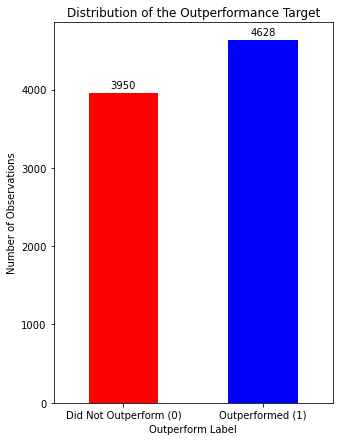

In [10]:
print("Target counts:")
print(df["Outperform"].value_counts().sort_index())

print("\nTarget percentages:")
print(df["Outperform"].value_counts(normalize=True).sort_index().mul(100))
# we normalize here to get decimal values for each classs (0,1) mul here gets us the percentages

target_counts = df["Outperform"].value_counts().sort_index()

ax = target_counts.plot(kind="bar", figsize=(5, 7),color=["red", "blue"])

# Add the numbers on top of each bar
ax.bar_label(ax.containers[0], padding=3)

plt.title("Distribution of the Outperformance Target")
plt.xlabel("Outperform Label")
plt.ylabel("Number of Observations")
plt.xticks(ticks=[0, 1], labels=["Did Not Outperform (0)", "Outperformed (1)"], rotation=0)
plt.show()


The two classes are reasonably balanced, although outperforming observations are slightly more common. This means the model will not be trained on a target dominated by only one outcome.


### 8. Create calendar quarters and inspect cross-sectional coverage

Individual dates contain too few stocks for meaningful ranking. The observations are therefore grouped into calendar quarters, which will later become the portfolio-construction periods.


Quarter
2003Q4    181
2004Q1     85
2004Q2    180
2004Q3    239
2004Q4    283
2005Q1    333
2005Q2    202
2005Q3     86
2005Q4     57
2006Q1    108
2006Q2    200
2006Q3    136
2006Q4    105
2007Q1    297
2007Q2    291
2007Q3     70
2007Q4    145
2008Q1    202
2008Q2    123
2008Q3     13
2008Q4    222
2009Q1    174
2009Q2     42
2009Q3     56
2009Q4     52
2010Q1     48
2010Q2     18
2010Q3     20
2010Q4     33
2011Q1     43
2011Q2    119
2011Q3    253
2011Q4    270
2012Q1    228
2012Q2    146
2012Q3    166
2012Q4    164
2013Q1    144
2013Q2    462
2013Q3     28
Freq: Q-DEC, Name: Ticker, dtype: int64

Quarterly stock-count summary:

count     40.000000
mean     150.600000
std      102.248767
min       13.000000
25%       56.750000
50%      144.500000
75%      207.000000
max      462.000000
Name: Ticker, dtype: float64


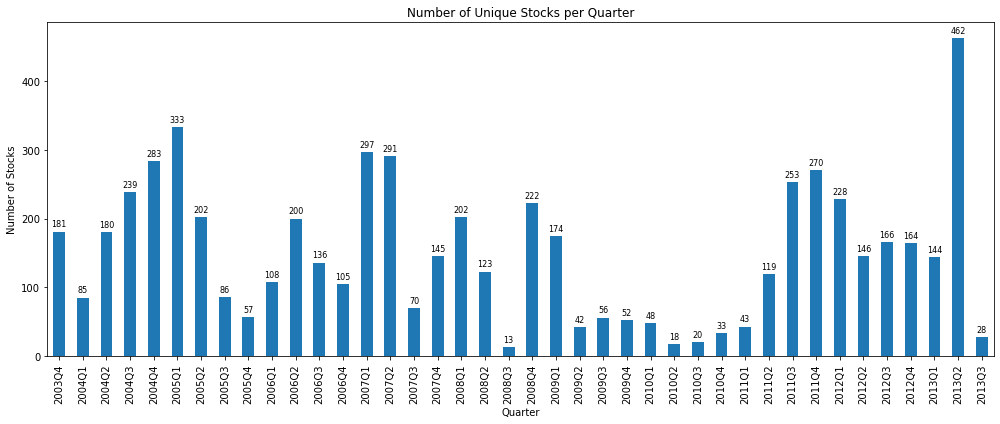

In [11]:
# creating the quarterly calendar variable
df["Quarter"] = df["Date"].dt.to_period("Q")

stocks_per_quarter = df.groupby("Quarter")["Ticker"].nunique().sort_index()

print(stocks_per_quarter)
print("\nQuarterly stock-count summary:\n")
print(stocks_per_quarter.describe())

ax = stocks_per_quarter.plot(kind="bar", figsize=(14, 6))
plt.title("Number of Unique Stocks per Quarter")
plt.xlabel("Quarter")
plt.ylabel("Number of Stocks")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
plt.tight_layout()
plt.show()


The number of available stocks varies substantially across quarters. Most quarters provide a meaningful cross-section, but a small number contain fewer than 30 stocks. Ranking very small groups could create unstable and less comparable long/short portfolios.


### 9. Exclude extremely thin quarters

A minimum threshold of 30 unique stocks is used based on visual observation. This removes only the clearest low-coverage quarters while preserving thinner but still usable periods for later analysis.


In [12]:
# Show the 10 quarters with the fewest unique stocks
print(stocks_per_quarter.sort_values().head(10), "\n")

MIN_STOCKS = 30

thin_quarters = stocks_per_quarter[stocks_per_quarter < MIN_STOCKS]
print("Quarters below the threshold, to be excluded:\n\n",thin_quarters )


valid_quarters = stocks_per_quarter[stocks_per_quarter >= MIN_STOCKS].index

df = df[df["Quarter"].isin(valid_quarters)].reset_index(drop=True)

print("\nRemaining quarters:", df["Quarter"].nunique())
print("Remaining rows:", len(df))

remaining_counts = df.groupby("Quarter")["Ticker"].nunique().sort_index()
still_thin = remaining_counts[remaining_counts < 60]

print("\nRetained quarters that remain relatively thin:")
print(still_thin)


Quarter
2008Q3    13
2010Q2    18
2010Q3    20
2013Q3    28
2010Q4    33
2009Q2    42
2011Q1    43
2010Q1    48
2009Q4    52
2009Q3    56
Freq: Q-DEC, Name: Ticker, dtype: int64 

Quarters below the threshold, to be excluded:

 Quarter
2008Q3    13
2010Q2    18
2010Q3    20
2013Q3    28
Freq: Q-DEC, Name: Ticker, dtype: int64

Remaining quarters: 36
Remaining rows: 8485

Retained quarters that remain relatively thin:
Quarter
2005Q4    57
2009Q2    42
2009Q3    56
2009Q4    52
2010Q1    48
2010Q4    33
2011Q1    43
Freq: Q-DEC, Name: Ticker, dtype: int64


Four quarters fall below the 30-stock requirement and are excluded. Several retained quarters remain smaller than the typical quarter, so their eventual portfolio results should be interpreted cautiously because each selected stock will carry greater influence.


### 10. Review features with substantial missing data

Several fundamental variables contain noticeably more missing values than the rest of the dataset, particularly the quarterly growth and cash flow measures. Rather than removing these features immediately, they are reviewed individually to determine whether enough information remains for modeling. Since each variable still contains several thousand valid observations, they are retained. Missing values will instead be imputed after the chronological train-test split using statistics calculated from the training data only, preventing data leakage.


In [13]:
df.isnull().sum().sort_values().tail(5)


Total debt/equity         1409
Qtrly revenue growth      2077
Operating cash flow       2723
Qtrly earnings growth     2882
Levered free cash flow    3127
dtype: int64

### 11. Check for infinite numerical values

Financial ratios can become infinite when a denominator is zero or extremely close to zero. Infinite values cannot be used directly by the model, so the numerical columns are checked before modeling.


In [14]:
numeric_columns = df.select_dtypes(include=np.number).columns
infinite_counts = pd.Series({column: np.isinf(df[column]).sum() for column in numeric_columns})

print("Columns containing infinite values:")
print(infinite_counts[infinite_counts > 0].sort_values(ascending=False))


Columns containing infinite values:
Series([], dtype: int64)


No infinite values were found in the current data.


### 12. Focused descriptive statistics and boxplots

A selected group of familiar financial features is used to demonstrate differences in scale and distribution without displaying every variable. The y-axis is restricted so that the central portions of the boxplots remain readable. Extreme observations are not deleted at this stage.


In [15]:
selected_features = [
    "Trailing p/e",
    "Forward p/e",
    "Peg ratio",
    "Profit margin",
    "Return on equity",
    "Total debt/equity",
    "Beta",
    "Short ratio"
]

df[selected_features].describe().T


,count,mean,std,min,25%,50%,75%,max
Trailing p/e,7744.0,39.964560,369.857711,0.000,13.0375,18.0650,25.2725,12795.00
Forward p/e,8186.0,17.339659,29.181493,0.000,11.0500,14.2100,17.9800,1792.00
Peg ratio,8060.0,1.738577,11.235281,-342.500,1.0100,1.3500,1.8300,685.00
Profit margin,8365.0,10.789378,17.883422,-282.140,4.8600,9.4000,16.8200,157.14
Return on equity,8199.0,25.527879,152.340997,-1642.390,9.6200,16.5800,24.2600,3544.63
Total debt/equity,7076.0,41.924157,259.077969,-13.342,0.3460,1.0360,32.4475,16174.36
Beta,7992.0,1.183227,0.813001,-2.530,0.6200,1.0685,1.5900,6.35
Short ratio,8406.0,3.557015,2.915274,0.000,1.8000,2.7000,4.3420,31.60


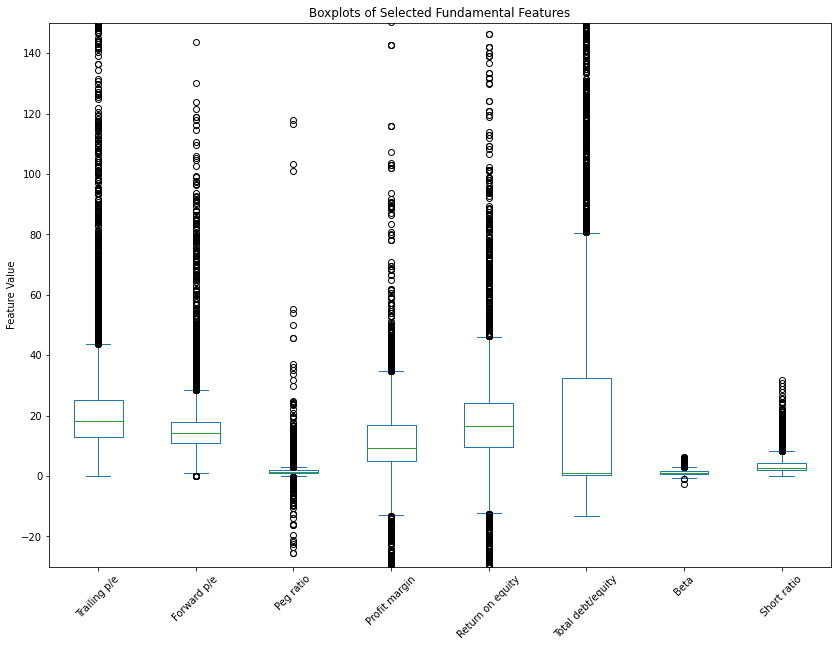

In [16]:
df[selected_features].plot(kind="box", figsize=(14, 10), rot=45)
plt.ylim(-30, 150)
plt.title("Boxplots of Selected Fundamental Features")
plt.ylabel("Feature Value")
plt.show()


The selected features operate on very different scales and several have long-tailed distributions. This is common for financial ratios. Random Forests do not require standardization in the same way as distance-based or linear models, but extreme values may still affect individual tree splits. The values are examined here but not capped or removed before the train/test split.


### 13. Define the candidate model features and inspect correlation

Identifier fields, market levels, forward-return outcomes, the target, and the quarter variable must not enter the Random Forest as predictors. In particular, the two forward percentage-change columns are excluded because using them would create direct target leakage.

The correlation analysis is diagnostic. No correlated predictors are removed at this stage; any data-changing decision should be determined from the training period only.


In [17]:
exclude_columns = ["Date", "Unix", "Ticker", "Price",
                   "Stock_p_change", "Sp500", "Sp500_p_change",
                   "Quarter", "Outperform"]

feature_columns = [column for column in df.columns if column not in exclude_columns]

print("Number of candidate fundamental features:", len(feature_columns))
print(feature_columns)


Number of candidate fundamental features: 41
['Market cap', 'Enterprise value', 'Trailing p/e', 'Forward p/e', 'Peg ratio', 'Price/sales', 'Price/book', 'Enterprise value/revenue', 'Enterprise value/ebitda', 'Profit margin', 'Operating margin', 'Return on assets', 'Return on equity', 'Revenue', 'Revenue per share', 'Qtrly revenue growth', 'Gross profit', 'Ebitda', 'Net income avl to common', 'Diluted eps', 'Qtrly earnings growth', 'Total cash', 'Total cash per share', 'Total debt', 'Total debt/equity', 'Current ratio', 'Book value per share', 'Operating cash flow', 'Levered free cash flow', 'Beta', '50-day moving average', '200-day moving average', 'Avg vol (3 month)', 'Shares outstanding', 'Float', '% held by insiders', '% held by institutions', 'Shares short (as of', 'Short ratio', 'Short % of float', 'Shares short (prior month)']


In [18]:
correlation_matrix = df[feature_columns].corr()
# print(correlation_matrix)

high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i,j]) >=0.8:
            high_corr_pairs.append([correlation_matrix.columns[i],
                                    correlation_matrix.columns[j],correlation_matrix.iloc[i,j]])

high_corr_pairs_df = pd.DataFrame(
    high_corr_pairs,
    columns = ["Feature 1", "Feature 2", "Correlation"]).sort_values("Correlation", key = abs)

print("Number of feature pairs with |correlation| >= 0.80:", len(high_corr_pairs_df))
high_corr_pairs_df.head(20)


Number of feature pairs with |correlation| >= 0.80: 21


,Feature 1,Feature 2,Correlation
3,Gross profit,Revenue,0.800820
2,Gross profit,Market cap,0.811399
5,Ebitda,Enterprise value,0.817186
0,Enterprise value,Market cap,0.831348
6,Ebitda,Revenue,0.836625
8,Net income avl to common,Market cap,0.846393
13,Total debt,Total cash,0.854689
4,Ebitda,Market cap,0.876453
14,Book value per share,Revenue per share,0.910809
7,Ebitda,Gross profit,0.911788


Several fundamental measures are strongly related because they capture similar aspects of valuation, company size, cash flow, or ownership. Random Forests are more tolerant of correlated predictors than many linear models, but correlation can divide feature importance across similar variables and make interpretation less clear. The variables are retained for now, and their importance will be reassessed after the model is trained.


## Part 1 conclusion

The raw dataset has now been organized into a structure suitable for chronological model development:

- dates and ticker symbols are standardized;
- observations without valid forward stock returns are removed;
- a binary outperformance target is created;
- observations are organized into calendar quarters;
- quarters with fewer than 30 unique stocks are excluded;
- features with substantial missingness are retained for later training-only imputation;
- infinite values and selected feature distributions are inspected;
- candidate model features are separated from identifiers and future outcome information;
- correlations are examined without making premature feature-removal decisions.

The next stage divides the observations chronologically into training and testing periods. After the split, missing predictor values will be filled using statistics calculated from the training data only.


# Part 2: Chronological Train-Test Split

A random split would mix earlier and later market observations. That would not reflect how the model would be used in practice, because a real investment model must learn from historical information before making predictions about later periods.

After filtering the very thin quarters, 36 usable quarters remain. The most recent 10 available quarters are reserved for out-of-sample testing, while the preceding 26 quarters are used for training. This provides a substantial training history while retaining enough quarterly test periods for the later portfolio-performance and risk analysis.


### 14. Identify the available quarters

The quarters are sorted chronologically so that the cutoff can be selected from the actual periods remaining after the earlier filtering step.


In [19]:
# Store the usable calendar quarters in chronological order
quarters = sorted(df["Quarter"].unique())

print(quarters)
print("\nNumber of available quarters:", len(quarters))


[Period('2003Q4', 'Q-DEC'), Period('2004Q1', 'Q-DEC'), Period('2004Q2', 'Q-DEC'), Period('2004Q3', 'Q-DEC'), Period('2004Q4', 'Q-DEC'), Period('2005Q1', 'Q-DEC'), Period('2005Q2', 'Q-DEC'), Period('2005Q3', 'Q-DEC'), Period('2005Q4', 'Q-DEC'), Period('2006Q1', 'Q-DEC'), Period('2006Q2', 'Q-DEC'), Period('2006Q3', 'Q-DEC'), Period('2006Q4', 'Q-DEC'), Period('2007Q1', 'Q-DEC'), Period('2007Q2', 'Q-DEC'), Period('2007Q3', 'Q-DEC'), Period('2007Q4', 'Q-DEC'), Period('2008Q1', 'Q-DEC'), Period('2008Q2', 'Q-DEC'), Period('2008Q4', 'Q-DEC'), Period('2009Q1', 'Q-DEC'), Period('2009Q2', 'Q-DEC'), Period('2009Q3', 'Q-DEC'), Period('2009Q4', 'Q-DEC'), Period('2010Q1', 'Q-DEC'), Period('2010Q4', 'Q-DEC'), Period('2011Q1', 'Q-DEC'), Period('2011Q2', 'Q-DEC'), Period('2011Q3', 'Q-DEC'), Period('2011Q4', 'Q-DEC'), Period('2012Q1', 'Q-DEC'), Period('2012Q2', 'Q-DEC'), Period('2012Q3', 'Q-DEC'), Period('2012Q4', 'Q-DEC'), Period('2013Q1', 'Q-DEC'), Period('2013Q2', 'Q-DEC')]

Number of available quarte

The cleaned dataset contains 36 usable quarters. Some calendar quarters are absent because they contained fewer than 30 stocks and were removed during Part 1.


### 15. Reserve the most recent 10 quarters for testing

The tenth quarter from the end is used as the beginning of the testing period. All observations before that quarter form the training set, and all observations from that quarter onward form the testing set.


In [20]:
# Use the most recent 10 available quarters as the out-of-sample test period
test_start = quarters[-10]

# Split chronologically so the model trains only on earlier observations
train_df = df[df["Quarter"] < test_start]
test_df = df[df["Quarter"] >= test_start]

# Verify the time periods and sample sizes
print("Testing period starts:", test_start)
print("\nTraining quarters:", train_df["Quarter"].nunique())
print("Testing quarters:", test_df["Quarter"].nunique())

print("\nTraining period:", train_df["Quarter"].min(), "to", train_df["Quarter"].max())
print("Testing period:", test_df["Quarter"].min(), "to", test_df["Quarter"].max())

print("\nTraining observations:", len(train_df))
print("Testing observations:", len(test_df))


Testing period starts: 2011Q1

Training quarters: 26
Testing quarters: 10

Training period: 2003Q4 to 2010Q4
Testing period: 2011Q1 to 2013Q2

Training observations: 5550
Testing observations: 2935


The training period contains 26 quarters from 2003Q4 through 2010Q4, while the testing period contains 10 quarters from 2011Q1 through 2013Q2. The testing observations remain completely separate from the data used to estimate the model and its preprocessing values.


# Part 3: Training-Set Preprocessing

The predictor variables and target are now separated. Any transformation that learns a value from the data must be based only on the training set. This is especially important for missing-value imputation because calculating medians from the full dataset would allow information from the later testing period to influence model preparation.


### 16. Separate the predictors from the target

`X_train` and `X_test` contain the 41 candidate company features. `y_train` and `y_test` contain the binary `Outperform` label.


In [21]:
# Separate the candidate features from the binary target
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df["Outperform"]
y_test = test_df["Outperform"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (5550, 41)
X_test shape: (2935, 41)

y_train shape: (5550,)
y_test shape: (2935,)


The predictor and target dimensions agree within each period: every training row has one training label, and every testing row has one testing label. The same 41 feature columns are present in both predictor sets.


### 17. Examine missingness in the training predictors

Missingness is evaluated using `X_train` only. This reveals how much information is available during the period from which the model will actually learn.


In [22]:
# Count and calculate the percentage of missing values in the training predictors
train_missing = X_train.isnull().sum().sort_values(ascending=False)
train_missing_percent = X_train.isnull().mean().sort_values(ascending=False).mul(100)

print("Training features with missing values:")
print(train_missing[train_missing > 0])

print("\nTraining feature missing percentages:")
print(train_missing_percent[train_missing_percent > 0])


Training features with missing values:
Levered free cash flow        2638
Qtrly earnings growth         2432
Operating cash flow           2423
Qtrly revenue growth          2014
Total debt/equity              965
Current ratio                  695
Enterprise value/ebitda        669
Ebitda                         543
Trailing p/e                   505
Beta                           412
Peg ratio                      364
Float                          287
Forward p/e                    201
Return on assets               178
Return on equity               175
Operating margin               175
Price/book                     152
Enterprise value/revenue       135
Short % of float               133
% held by insiders             123
Enterprise value               113
Profit margin                  111
Gross profit                    98
Total debt                      95
% held by institutions          95
200-day moving average          95
Price/sales                     93
Total cash      

The quarterly growth and cash-flow variables have the highest missingness in the training period. In particular, several of them are missing for more than 40% of the training observations. They are nevertheless retained because each still contains thousands of observed values and may contribute useful financial information. This choice is a limitation to discuss later: median imputation preserves the variables but cannot recreate the company-specific information that is absent.


### 18. Impute missing values with training-set medians

The median is used because many financial variables are skewed and contain extreme observations. It is therefore less affected by unusually large or small values than the mean.

The medians are calculated from `X_train` only. Those same training medians are then applied to both `X_train` and `X_test`, preventing the testing period from influencing preprocessing.


In [23]:
# Calculate one median for each feature using only the training period
train_medians = X_train.median()

# Fill missing values in both sets with the training-set medians
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# Confirm that the model inputs no longer contain missing values
print("Total missing values in X_train:", X_train.isnull().sum().sum())
print("Total missing values in X_test:", X_test.isnull().sum().sum())


Total missing values in X_train: 0
Total missing values in X_test: 0


Both predictor sets now contain zero missing values and can be passed to the Random Forest. The variables are not standardized because decision-tree models split features at numerical thresholds and do not require all predictors to share the same scale.


### 19. Compare the target distributions across periods

The proportion of outperformers is examined separately in the training and testing sets. A shift between the two periods may reflect changing market conditions rather than a data-processing error.


In [24]:
# Compare the percentage of each target class across the two time periods
print("Training target percentages:")
print(y_train.value_counts(normalize=True).sort_index().mul(100))

print("\nTesting target percentages:")
print(y_test.value_counts(normalize=True).sort_index().mul(100))


Training target percentages:
Outperform
0    43.765766
1    56.234234
Name: proportion, dtype: float64

Testing target percentages:
Outperform
0    49.914821
1    50.085179
Name: proportion, dtype: float64


The training period contains a somewhat larger share of outperforming observations, while the testing period is almost evenly divided between the two classes. This difference reinforces the need to evaluate the model on later observations rather than relying only on its training performance.


### 20. Final preprocessing verification

The final check summarizes the number of predictors and observations and confirms that no missing values remain before model training.


In [25]:
# Final verification before fitting the Random Forest
print("Number of model features:", X_train.shape[1])
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("\nTotal missing values in training data:", X_train.isnull().sum().sum())
print("Total missing values in testing data:", X_test.isnull().sum().sum())


Number of model features: 41
Training observations: 5550
Testing observations: 2935

Total missing values in training data: 0
Total missing values in testing data: 0


## Parts 2 and 3 conclusion

The data have now been divided chronologically into an earlier training period and a later out-of-sample testing period. The predictors and target have been separated, and all missing predictor values have been filled using medians calculated only from the training data.

The following objects are ready for the modeling stage:

- `X_train` and `y_train` for fitting the Random Forest;
- `X_test` and `y_test` for out-of-sample evaluation;
- `train_df` and `test_df` for reconnecting predictions to tickers, quarters, and realized returns during portfolio construction.

Part 4 will train a baseline Random Forest classifier, compare its training and testing performance, generate outperformance probabilities, and examine feature importance.


# Part 4: Random Forest Classification

The prepared training data are now used to build a baseline Random Forest classifier. The purpose of this section is not only to generate binary predictions, but also to estimate each stock's probability of outperforming the S&P 500. Those probabilities will later be used to rank stocks and construct the long/short portfolio.

A baseline model is used first so that its behavior can be understood before introducing additional tuning. The model contains 100 decision trees, and `random_state=42` makes the results reproducible.


### 21. Train the baseline Random Forest

The model learns the relationship between the 41 candidate features and the binary `Outperform` target using only the chronological training period. Predictions are then generated for both the training and testing sets so that in-sample and out-of-sample performance can be compared.


In [26]:
# Import the Random Forest model and classification metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Create and train the baseline Random Forest
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest.fit(X_train, y_train)

# Generate class predictions for the training and testing periods
y_train_predictions = random_forest.predict(X_train)
y_test_predictions = random_forest.predict(X_test)

# Compare model accuracy with the majority-class baseline
train_accuracy = accuracy_score(y_train, y_train_predictions)
test_accuracy = accuracy_score(y_test, y_test_predictions)
baseline_accuracy = y_test.value_counts(normalize=True).max()

print("Training Accuracy:", train_accuracy * 100)
print("Testing Accuracy:", test_accuracy * 100)
print("Baseline Accuracy:", baseline_accuracy * 100)


Training Accuracy: 99.56756756756758
Testing Accuracy: 49.13117546848382
Baseline Accuracy: 50.08517887563884


The model achieves nearly perfect training accuracy but performs close to 49% on the testing data, slightly below the majority-class baseline. The large gap between training and testing accuracy indicates substantial overfitting: the unrestricted trees learn the training observations extremely well but do not generalize effectively to later quarters.

This result does not automatically end the project. The central portfolio question is whether the predicted probabilities still provide a useful relative ranking of stocks, even when the binary classifications themselves are weak.


### 22. Evaluate the testing predictions

Accuracy alone does not show how the model performs on each class. Precision, recall, the F1 score, the classification report, and the confusion matrix provide a more complete view of the testing results.


Accuracy: 0.4913117546848382
Precision: 0.49382716049382713
Recall: 0.6258503401360545
F1 Score: 0.552055205520552

Classification report:
              precision    recall  f1-score   support

           0       0.49      0.36      0.41      1465
           1       0.49      0.63      0.55      1470

    accuracy                           0.49      2935
   macro avg       0.49      0.49      0.48      2935
weighted avg       0.49      0.49      0.48      2935

Confusion matrix:

 [[522 943]
 [550 920]]


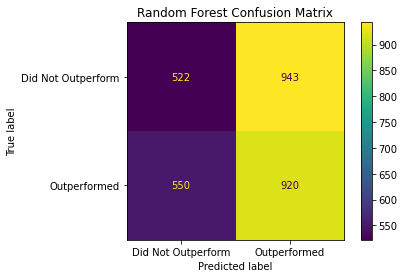

In [27]:
# Calculate the main out-of-sample classification metrics
print("Accuracy:", accuracy_score(y_test, y_test_predictions))
print("Precision:", precision_score(y_test, y_test_predictions))
print("Recall:", recall_score(y_test, y_test_predictions))
print("F1 Score:", f1_score(y_test, y_test_predictions))

print("\nClassification report:")
print(classification_report(y_test, y_test_predictions))

# Calculate and display the confusion matrix
confusion_matrix_results = confusion_matrix(y_test, y_test_predictions)
print("Confusion matrix:\n\n", confusion_matrix_results)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_results,
    display_labels=["Did Not Outperform", "Outperformed"]
).plot()

plt.title("Random Forest Confusion Matrix")
plt.show()


The model has higher recall for the outperforming class than for the non-outperforming class. In other words, it identifies a larger share of the stocks that actually outperform, but it also produces many false positives. Precision is approximately 49%, meaning that fewer than half of the stocks predicted to outperform actually do so in the testing period.

The confusion matrix confirms that the model tends to predict the outperformance class more frequently. These findings are consistent with the weak overall testing accuracy and reinforce the need to treat the model as a ranking tool rather than as a certain trading instruction.


### 23. Generate outperformance probabilities

`predict_proba()` produces one probability for each class. Column 0 represents the estimated probability of not outperforming, while column 1 represents the estimated probability of outperforming. Only the class-1 probabilities are retained because they will be used to rank the stocks.


In [28]:
# Generate each testing observation's estimated probability of outperforming
test_probabilities = random_forest.predict_proba(X_test)[:, 1]

print(test_probabilities[:20])

# Reconnect the model outputs to the stock and realized-return information
test_results = test_df[
    ["Date", "Quarter", "Ticker", "Stock_p_change", "Sp500_p_change", "Outperform"]
].copy()

test_results["Predicted_class"] = y_test_predictions
test_results["Outperform_probability"] = test_probabilities

test_results.sort_values("Outperform_probability").head(20)


[0.53 0.94 0.67 0.44 0.49 0.63 0.44 0.4  0.94 0.58 0.57 0.66 0.91 0.48
 0.39 0.65 0.6  0.5  0.57 0.89]


,Date,Quarter,Ticker,Stock_p_change,Sp500_p_change,Outperform,Predicted_class,Outperform_probability
5665,2011-04-29,2011Q2,JPM,-2.26,5.07,0,0,0.10
6242,2011-11-04,2011Q4,JPM,28.60,15.23,1,0,0.17
5966,2011-09-03,2011Q3,JPM,10.60,22.32,0,0,0.18
5875,2011-08-17,2011Q3,BK,10.95,21.17,0,0,0.25
6562,2012-01-03,2012Q1,JPM,32.38,17.10,1,0,0.25
6889,2012-03-09,2012Q1,JPM,25.95,15.50,1,0,0.25
5769,2011-07-02,2011Q3,TDC,18.22,3.79,1,0,0.26
6803,2012-02-26,2012Q1,DO,7.91,11.23,0,0,0.26
5771,2011-07-03,2011Q3,TDC,18.01,4.10,1,0,0.26
5857,2011-08-14,2011Q3,TSLA,18.47,21.71,0,0,0.27


The resulting table connects each prediction to its date, quarter, ticker, realized stock return, S&P 500 return, and actual target. This is necessary because the model itself receives only the predictor matrix. The probability column becomes the main signal used for quarterly portfolio construction.


### 24. Examine Random Forest feature importance

Feature importance measures the relative contribution of each predictor to the forest's decision rules. It does not establish causation, and correlated variables may divide importance between themselves. The results are therefore interpreted as an indication of which variables the fitted model relied on most heavily.


                    Feature  Importance
11         Return on assets    0.025419
31   200-day moving average    0.025434
38              Short ratio    0.025740
15     Qtrly revenue growth    0.025777
21               Total cash    0.025848
8   Enterprise value/ebitda    0.025996
26     Book value per share    0.026043
36   % held by institutions    0.026111
23               Total debt    0.027250
29                     Beta    0.027458
1          Enterprise value    0.027526
22     Total cash per share    0.027690
13                  Revenue    0.027998
0                Market cap    0.028165
16             Gross profit    0.028822


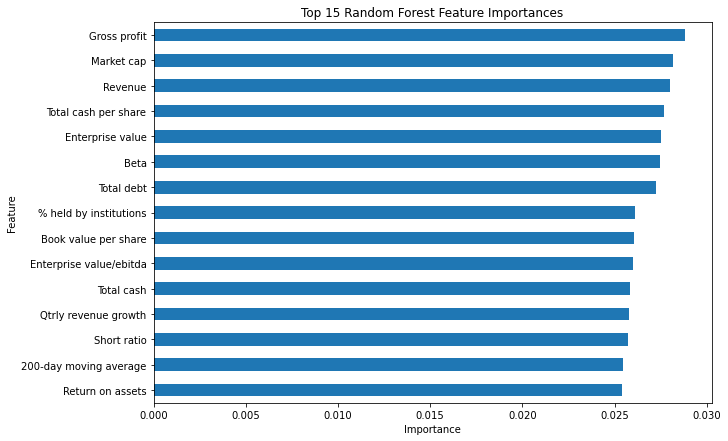

In [29]:
# Organize the Random Forest feature importances from highest to lowest
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

print(feature_importance.head(15).sort_values("Importance"))

feature_importance.head(15).sort_values("Importance").plot(
    kind="barh",
    x="Feature",
    y="Importance",
    figsize=(10, 7),
    legend=False
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


The leading features include measures of company size, revenue, cash, debt, profitability, market risk, and short interest. Their importance values are relatively close to one another, suggesting that the forest relies on information distributed across many predictors rather than one overwhelmingly dominant feature.

Because several of these variables are strongly correlated, the exact ranking should be interpreted cautiously. Feature importance describes how this particular fitted forest used the variables; it does not prove that the highest-ranked feature independently causes future outperformance.


## Part 4 conclusion

The baseline Random Forest fits the training period extremely closely but does not outperform the simple majority-class benchmark on the later testing period. This is clear evidence of overfitting and weak out-of-sample classification performance.

Despite that limitation, the model produces a wide range of outperformance probabilities. Part 5 therefore tests whether those probabilities contain enough relative information to rank stocks within each quarter and form a systematic long/short portfolio.


# Part 5: Quarterly Stock Ranking and Portfolio Construction

The predicted class alone divides observations into only two groups. For portfolio construction, the predicted probability is more useful because it provides a continuous measure of the model's relative confidence.

Stocks are ranked separately within each testing quarter. The highest-ranked 10% are assigned to the long portfolio, while the lowest-ranked 10% are assigned to the short portfolio. Equal-sized long and short books are used so that the strategy remains balanced by design.


### 25. Retain one observation per stock in each quarter

Some tickers appear on multiple dates within the same quarter. Ranking every row would allow the same company to occupy several portfolio positions. To ensure that the portfolio ranks unique stocks, only the latest available observation for each `(Quarter, Ticker)` combination is retained.


In [30]:
# Keep the latest available observation for each stock within each quarter
test_results = (
    test_results.sort_values("Date")
    .groupby(["Quarter", "Ticker"])
    .tail(1)
    .reset_index(drop=True)
)


This step changes the unit being ranked from individual stock-date observations to unique stocks within each quarter. The latest observation is used because it represents the most recent record available for that company during the quarter.


### 26. Rank stocks within each quarter

The observations are sorted from the highest to the lowest predicted probability. A unique integer rank is then assigned within each quarter. `method="first"` resolves tied probabilities according to their sorted row order so that every stock receives one distinct rank.


In [31]:
# Sort stocks within each quarter from highest to lowest predicted probability
test_results = test_results.sort_values(
    ["Quarter", "Outperform_probability"],
    ascending=[True, False]
).reset_index(drop=True)

# Assign a unique rank within each quarter
test_results["Quarterly_rank"] = (
    test_results.groupby("Quarter")["Outperform_probability"]
    .rank(method="first", ascending=False)
)

# Count the number of unique stocks available in each quarter
test_results["Quarter_size"] = (
    test_results.groupby("Quarter")["Ticker"]
    .transform("count")
)


The ranking restarts at 1 in every quarter. Rank 1 represents the stock with the highest predicted probability of outperforming during that quarter, while the largest rank represents the lowest predicted probability.


### 27. Assign the long and short portfolios

The top and bottom 10% of each quarter's stock universe are selected. The portfolio size is calculated once and applied symmetrically to both sides. Converting the decile size to an integer produces equal long and short counts even when 10% of the quarter size is fractional.


In [32]:
# Use the top and bottom 10% of stocks in each quarter
DECILE = 0.10

# Calculate one equal portfolio size for the long and short sides
test_results["Portfolio_size"] = (
    test_results["Quarter_size"] * DECILE
).astype(int)

# Begin with no assigned portfolio position
test_results["Position"] = "None"

# Assign the highest-ranked stocks to the long portfolio
test_results.loc[
    test_results["Quarterly_rank"] <= test_results["Portfolio_size"],
    "Position"
] = "Long"

# Assign the lowest-ranked stocks to the short portfolio
test_results.loc[
    test_results["Quarterly_rank"] > test_results["Quarter_size"] - test_results["Portfolio_size"],
    "Position"
] = "Short"


A percentage-based rule is preferable to selecting a fixed number of stocks because quarter sizes vary considerably. The same relative definition of the long and short groups is therefore maintained throughout the testing period.


### 28. Verify the portfolio construction

The final checks confirm that each quarter contains equal long and short books and that no ticker appears more than once in the same quarter.


In [33]:
# Verify the number of long and short positions in each quarter
position_counts = test_results.groupby(
    ["Quarter", "Position"]
).size().unstack(fill_value=0)

print(position_counts)

# Confirm that each ticker appears only once within each quarter
print(
    "\nDuplicate stock-quarter combinations:",
    test_results.duplicated(subset=["Quarter", "Ticker"]).sum()
)

print(
    "Maximum observations for any stock within a quarter:",
    test_results.groupby(["Quarter", "Ticker"]).size().max()
)

# Retain only the stocks selected for the long or short portfolios
selected_positions = test_results[
    test_results["Position"].isin(["Long", "Short"])
]

selected_positions.head(20)


Position  Long  None  Short
Quarter                    
2011Q1       4    35      4
2011Q2      11    97     11
2011Q3      25   203     25
2011Q4      27   216     27
2012Q1      22   184     22
2012Q2      14   118     14
2012Q3      16   134     16
2012Q4      16   132     16
2013Q1      14   116     14
2013Q2      46   370     46

Duplicate stock-quarter combinations: 0
Maximum observations for any stock within a quarter: 1


,Date,Quarter,Ticker,Stock_p_change,Sp500_p_change,Outperform,Predicted_class,Outperform_probability,Quarterly_rank,Quarter_size,Portfolio_size,Position
0,2011-03-28,2011Q1,XOM,6.26,10.05,0,1,0.78,1.0,43,4,Long
1,2011-02-26,2011Q1,FOSL,56.39,5.65,1,1,0.72,2.0,43,4,Long
2,2011-02-23,2011Q1,DLX,7.00,6.47,1,1,0.70,3.0,43,4,Long
3,2011-03-10,2011Q1,IGT,-0.91,8.09,0,1,0.67,4.0,43,4,Long
39,2011-03-12,2011Q1,RL,39.46,7.35,1,0,0.41,40.0,43,4,Short
40,2011-02-25,2011Q1,CPB,3.93,5.65,0,0,0.40,41.0,43,4,Short
41,2011-01-19,2011Q1,CTXS,2.35,4.65,0,0,0.39,42.0,43,4,Short
42,2011-03-03,2011Q1,DO,-7.63,5.04,0,0,0.32,43.0,43,4,Short
43,2011-06-24,2011Q2,XOM,9.63,7.48,1,1,0.81,1.0,119,11,Long
44,2011-04-01,2011Q2,PKI,6.13,7.98,0,1,0.78,2.0,119,11,Long


The verification results show equal long and short counts in every testing quarter. The portfolio size scales from four stocks on each side in the smallest quarter to 46 stocks on each side in the largest quarter. There are no duplicate stock-quarter combinations, and the maximum number of observations for any ticker within a quarter is one.

The selected portfolios still contain individual prediction errors. Some long positions fail to outperform, and some short positions subsequently perform well. Part 6 will determine whether the long group nevertheless earns a higher average return than the short group across the testing quarters.


## Part 5 conclusion

The model probabilities have now been converted into a consistent portfolio-construction rule:

- one latest observation is retained for each stock in each quarter;
- stocks are ranked by predicted outperformance probability;
- the top decile forms the long portfolio;
- the bottom decile forms the short portfolio;
- both sides contain the same number of stocks;
- all selected positions are unique within each quarter.

Part 6 will calculate the average long return, average short return, and long-short return for each quarter. Those quarterly returns will then be used to evaluate cumulative performance and risk-adjusted results.


In [34]:
# part 6: Portfolio Return Evaluation


In [35]:
# we will calculate the long and short portfolios within each portfolio quarter.
portfolio_returns = selected_positions.groupby(["Quarter", "Position"])["Stock_p_change"].mean().unstack()
portfolio_returns


Position,Long,Short
Quarter,,
2011Q1,17.185000,9.527500
2011Q2,-2.902727,0.715455
2011Q3,31.829600,18.503200
2011Q4,19.178148,21.416667
2012Q1,21.990455,12.464545
2012Q2,18.902143,20.294286
2012Q3,77.755625,39.665625
2012Q4,37.963750,38.990000
2013Q1,43.122857,17.337857


In [36]:
# we will now calcualte the long-short return spread aka the difference between them

portfolio_returns["Long_short_return"] = (portfolio_returns["Long"] - portfolio_returns["Short"])
portfolio_returns


Position,Long,Short,Long_short_return
Quarter,,,
2011Q1,17.185000,9.527500,7.657500
2011Q2,-2.902727,0.715455,-3.618182
2011Q3,31.829600,18.503200,13.326400
2011Q4,19.178148,21.416667,-2.238519
2012Q1,21.990455,12.464545,9.525909
2012Q2,18.902143,20.294286,-1.392143
2012Q3,77.755625,39.665625,38.090000
2012Q4,37.963750,38.990000,-1.026250
2013Q1,43.122857,17.337857,25.785000


In [37]:
# we will calcualte the s&p 500 forward return usign the same stocks used for ranking

sp500_returns = (test_results.groupby("Quarter")["Sp500_p_change"].mean())

# add a sp500_returns column:
portfolio_returns["Sp500_return"] = sp500_returns

portfolio_returns


Position,Long,Short,Long_short_return,Sp500_return
Quarter,,,,
2011Q1,17.185000,9.527500,7.657500,6.080930
2011Q2,-2.902727,0.715455,-3.618182,4.545126
2011Q3,31.829600,18.503200,13.326400,22.649605
2011Q4,19.178148,21.416667,-2.238519,15.806889
2012Q1,21.990455,12.464545,9.525909,14.795044
2012Q2,18.902143,20.294286,-1.392143,22.565411
2012Q3,77.755625,39.665625,38.090000,22.276928
2012Q4,37.963750,38.990000,-1.026250,27.559573
2013Q1,43.122857,17.337857,25.785000,21.420972


In [38]:
# summary of the distribution:
portfolio_returns.describe()


Position,Long,Short,Long_short_return,Sp500_return
count,10.000000,10.000000,10.000000,10.000000
mean,29.013246,19.586687,9.426559,17.567193
std,21.304715,12.040264,13.505962,7.454673
min,-2.902727,0.715455,-3.618182,4.545126
25%,18.971144,13.586344,-1.300670,15.048005
50%,23.549032,17.920529,7.906685,19.696211
75%,36.430213,21.136071,12.376277,22.493290
max,77.755625,39.665625,38.090000,27.559573


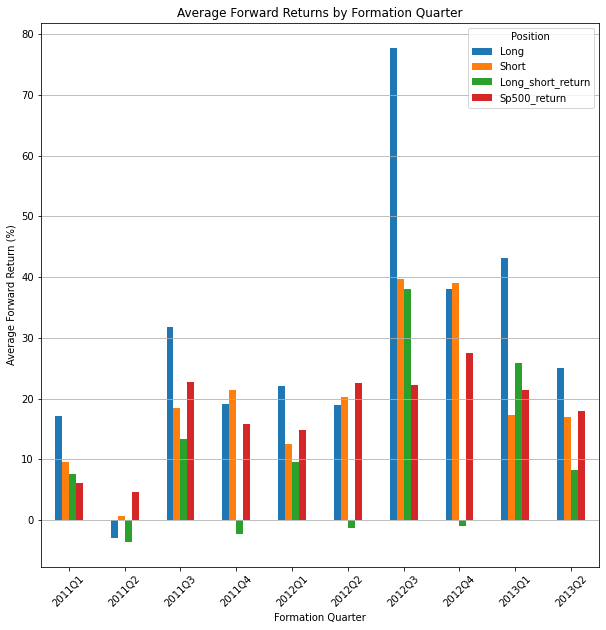

In [39]:
# Visualize the long, short, and long-short returns

portfolio_returns[["Long", "Short", "Long_short_return","Sp500_return" ]].plot(kind = "bar", figsize = (10,10))

plt.title("Average Forward Returns by Formation Quarter")
plt.xlabel("Formation Quarter")
plt.ylabel("Average Forward Return (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()


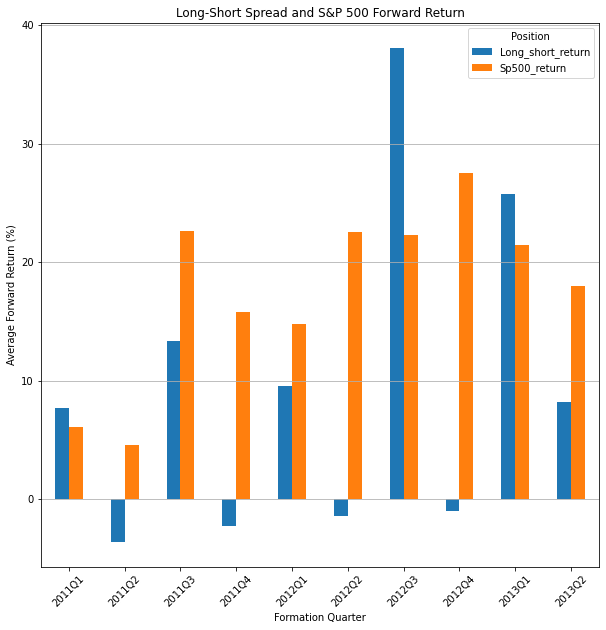

In [40]:
# comparing long short spread with s&p 500:

# Compare the long-short return spread with the market benchmark
portfolio_returns[['Long_short_return','Sp500_return' ]].plot(kind = "bar", figsize = (10,10))
plt.title("Long-Short Spread and S&P 500 Forward Return")
plt.title("Long-Short Spread and S&P 500 Forward Return")
plt.xlabel("Formation Quarter")
plt.ylabel("Average Forward Return (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()


In [41]:
#part 7 Risk Evaluation


In [42]:
# extracting and storing the quarterly long-short returns

stragery_returns = portfolio_returns["Long_short_return"]
stragery_returns_display = portfolio_returns[["Long_short_return"]]
stragery_returns_display


Position,Long_short_return
Quarter,
2011Q1,7.657500
2011Q2,-3.618182
2011Q3,13.326400
2011Q4,-2.238519
2012Q1,9.525909
2012Q2,-1.392143
2012Q3,38.090000
2012Q4,-1.026250
2013Q1,25.785000


In [43]:
# Calculate the average return and standard deviation, Calculate the Sharpe Ratio

average_return = stragery_returns.mean()

strategy_returns_std = stragery_returns.std()

# Calculate the quarterly Sharpe Ratio

sharpe_ratio = average_return / strategy_returns_std

print("Average Return:", average_return, "\n")
print("Standard Deviation:", strategy_returns_std, "\n")
print("Quarterly Sharpe Ratio:", sharpe_ratio)


Average Return: 9.42655854622833 

Standard Deviation: 13.50596212358234 

Quarterly Sharpe Ratio: 0.6979553518641156


In [44]:
# sortino ratio

# we first claculate the downside deviation

downside_returns = stragery_returns[stragery_returns < 0]
print(downside_returns)

downside_deviation = downside_returns.std()

# sortino ratio

sortino_ratio = average_return / downside_deviation

print("Downside Deviation:", downside_deviation)
print("Quarterly Sortino Ratio:", sortino_ratio)


Quarter
2011Q2   -3.618182
2011Q4   -2.238519
2012Q2   -1.392143
2012Q4   -1.026250
Freq: Q-DEC, Name: Long_short_return, dtype: float64
Downside Deviation: 1.1509653604211592
Quarterly Sortino Ratio: 8.1901322753788


In [45]:
# Historical value at risk, calcualte that:

historical_var_95 = stragery_returns.quantile(0.05)
print("Historical VaR (95%):", historical_var_95)


historical_cvar_95 = (stragery_returns[stragery_returns <= historical_var_95].mean())

print("Historical CVaR (95%):", historical_cvar_95)

# summarizign the risk metrics.

risk_summary = pd.DataFrame({

    "Metric": [
        "Average Return",
        "Standard Deviation",
        "Quarterly Sharpe Ratio",
        "Quarterly Sortino Ratio",
        "Historical VaR (95%)",
        "Historical CVaR (95%)"
    ],

    "Value": [
        average_return,
        strategy_returns_std,
        sharpe_ratio,
        sortino_ratio,
        historical_var_95,
        historical_cvar_95
    ]

})

risk_summary


Historical VaR (95%): -2.9973333333333345
Historical CVaR (95%): -3.618181818181818


,Metric,Value
0,Average Return,9.426559
1,Standard Deviation,13.505962
2,Quarterly Sharpe Ratio,0.697955
3,Quarterly Sortino Ratio,8.190132
4,Historical VaR (95%),-2.997333
5,Historical CVaR (95%),-3.618182
